# Chapitre 10 - Cours 2 : stockage distribué, workflows et pannes

Les outils Unix s'arrêtent aux limites d'une machine. Pour traiter des téraoctets, il
faut répartir les données **et** le calcul sur un cluster. Ce cours présente les briques
d'un tel « système d'exploitation distribué » : un système de fichiers distribué qui
découpe et réplique les fichiers, un ordonnanceur qui enchaîne les jobs d'un workflow,
et une stratégie de tolérance aux pannes adaptée à des jobs qui durent des heures. Il
couvre la section *MapReduce and Distributed Filesystems*, ainsi que *MapReduce workflows* et *Designing for frequent faults*.

**Plan.**

1. L'analogie du système d'exploitation distribué.
2. Le système de fichiers distribué : blocs, métadonnées, placement et localité.
3. Survivre aux pannes de disques : réplication ou codes d'effacement.
4. Les workflows : des graphes acycliques de jobs.
5. Pannes et préemption : relancer une tâche, pas tout le job.



In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)

## 1. Un système d'exploitation distribué (section *MapReduce and Distributed Filesystems*)

Sur la machine du cours 1, trois composants coopéraient : des **périphériques de
stockage** derrière l'interface du système de fichiers, un **ordonnanceur** du noyau qui
décide quel processus tourne sur quel cœur, et des **programmes** reliés par des
tuyaux. Un framework de traitement par lots distribué a exactement les mêmes
composants, à l'échelle d'un cluster. Le livre présente MapReduce comme un cousin des outils Unix, mais réparti sur des milliers de machines : à la place des fichiers locaux, un système de fichiers distribué (HDFS dans Hadoop) ; à la place de l'ordonnanceur du noyau, un gestionnaire de ressources du cluster (YARN pour Hadoop).

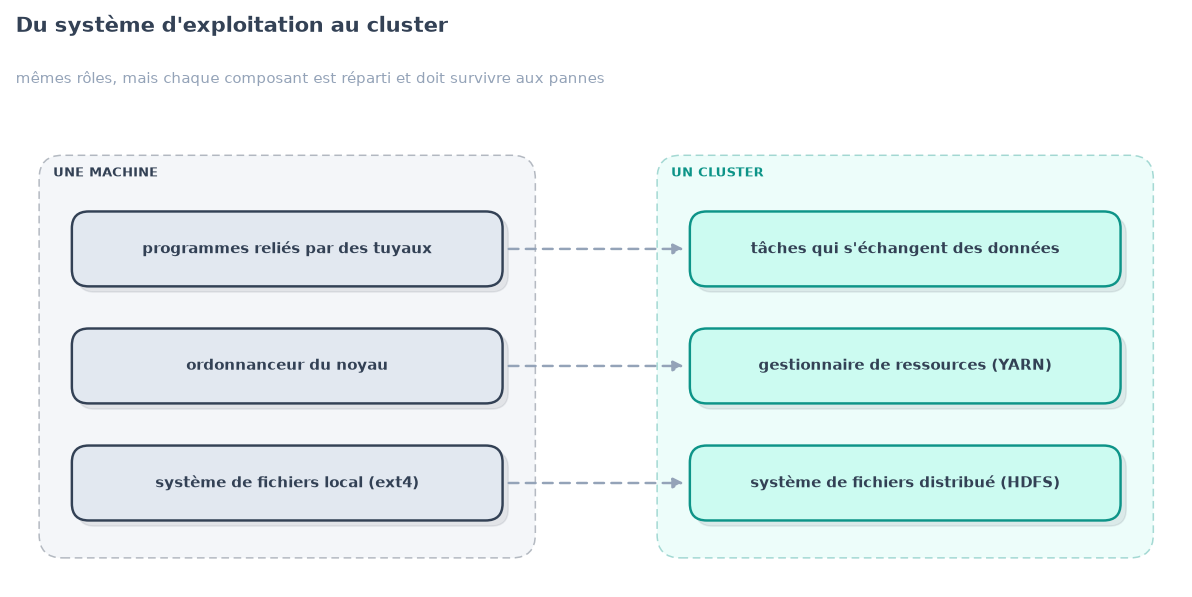

In [2]:
d = Diagram(12.5, 5.2, title="Du système d'exploitation au cluster",
            subtitle="mêmes rôles, mais chaque composant est réparti et doit survivre aux pannes")
d.group(0.3, 0.3, 5.6, 4.6, "une machine", color=SLATE)
d.group(6.9, 0.3, 12.2, 4.6, "un cluster", color=TEAL)
rows = [("programmes reliés par des tuyaux", "tâches qui s'échangent des données", 3.6),
        ("ordonnanceur du noyau", "gestionnaire de ressources (YARN)", 2.35),
        ("système de fichiers local (ext4)", "système de fichiers distribué (HDFS)", 1.1)]
for i, (a, b, y) in enumerate(rows):
    d.box(f"a{i}", 2.95, y, a, color=SLATE, w=4.6, h=0.8, fontsize=9.5)
    d.box(f"b{i}", 9.55, y, b, color=TEAL, w=4.6, h=0.8, fontsize=9.5)
    d.arrow(f"a{i}", f"b{i}", "", color=GRAY, style="dashed")
d.show()

> **À retenir.** Un framework de lots distribué est un « système d'exploitation » de
> cluster : un stockage partagé, un ordonnanceur, et des programmes qui se passent des
> données. Chaque brique doit en plus tolérer la panne d'une machine.